# Estadificación del sueño con DART y CRNN

Clasificación retrospectiva de épocas de 30 segundos en Sleep-Telemetry y Sleep-Cassette. La evaluación reserva personas completas de ambas cohortes. La combinación utiliza un LightGBM DART y una CRNN espectral contextual; ambos predicen las mismas cinco etapas. El ajuste final y la exportación con las 100 personas se realizan en [otro notebook](dart_crnn_mixto_final_100.ipynb).

### Hiperparámetros de LightGBM

DART usa **667 iteraciones** con una tasa de aprendizaje de **0,03**. Cada árbol tiene hasta **36 hojas**, profundidad máxima **8** y un mínimo de **25 segmentos por hoja**.

| Parámetro | Valor del modelo |
| --- | --- |
| Muestreo por iteración | 80 % de los segmentos y 60 % de las características |
| Regularización | L1 = 0,1, L2 = 1,5 |
| Descarte de árboles en DART | `drop_rate` = 0,1, `skip_drop` = 0,5 |
| Pesos por etapa | N1 = 2,2, N2 = 0,41, N3 = 1,56, REM = 1,0, W = 2,01 |
| Semilla | 42 |

### Arquitectura de la CRNN contextual

La red procesa **15 segmentos consecutivos de 30 segundos** (7,5 minutos). La convolución identifica patrones dentro de cada segmento y la GRU bidireccional usa los segmentos anteriores y posteriores de la ventana para estimar la etapa de sueño.

| Capa | Configuración y función |
| --- | --- |
| Entrada | 15 segmentos × 6 bloques de 5 s × 96 características. Las características combinan la potencia por banda de los dos EEG, el EOG y el EMG con su normalización y su contexto temporal. |
| Convolución por segmento | Conv1D con 48 filtros de ancho 3 y activación ReLU. Recorre los seis bloques y conserva una salida por bloque. |
| Resumen del segmento | Se aplanan las 6 × 48 salidas y una capa densa con ReLU las reduce a 48 valores. Dropout del 15 %. |
| Contexto entre segmentos | GRU bidireccional con 32 unidades por dirección. Las dos direcciones aportan 64 valores por segmento. Dropout del 20 %. |
| Salida | Una capa densa con softmax produce cinco probabilidades por segmento, una para cada etapa (N1, N2, N3, REM y W). |

**Entrenamiento.** Adam con tasa de aprendizaje 0,001, 15 épocas, lotes de 64 secuencias y semilla 42. En inferencia se combinan tres ventanas solapadas mediante una media geométrica. La distribución resultante aporta el 30 % de la mezcla final con DART en escala logarítmica.

In [1]:
import hashlib
import json
import os
import sys
from importlib.metadata import version
from pathlib import Path
from time import perf_counter
from uuid import uuid4

os.environ.setdefault('TF_ENABLE_ONEDNN_OPTS', '0')
os.environ.setdefault('TF_NUM_INTRAOP_THREADS', '5')
os.environ.setdefault('TF_NUM_INTEROP_THREADS', '1')
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '3')

import lightgbm as lgb
import matplotlib.pyplot as plt
import mne
import numpy as np
import pandas as pd
import tensorflow as tf
from scipy.fft import rfft
from scipy.ndimage import convolve1d
from scipy.special import softmax
from sklearn.metrics import accuracy_score, cohen_kappa_score, confusion_matrix, f1_score
from sklearn.model_selection import StratifiedKFold

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'data.dvc').is_file())
SRC = ROOT / 'packages/sleep-staging/src'
sys.path.insert(0, str(SRC))
from sleep_staging import PreprocessingConfig, PreprocessingPipeline
from sleep_staging.datasets import discover_sleep_cassette_records, discover_sleep_telemetry_records
from sleep_staging.training import create_lightgbm_classifier, load_or_build_supervised_dataset

inicio_ejecucion = perf_counter()
DATA = ROOT / 'data'
STORE = DATA / 'models/dart_crnn_mixto'
SPEC = json.loads((DATA / 'experimentos/lightgbm_st_sc/experimento.json').read_text('utf8'))
CLASES = np.array(SPEC['classes'])
COLUMNAS = SPEC['feature_columns']
PERFILES = {c: SPEC['preprocessing_' + c.lower()] for c in ('Telemetry', 'Cassette')}
CANALES = PERFILES['Telemetry']['channels']
PARAMS = dict(SPEC['parameters'], n_jobs=6)
BANDAS = [(0.3, 4), (4, 8), (8, 12), (12, 16), (16, 30), (30, 35)]
DESFASES = (0, 5, 10)
SEMILLA = 42
EPOCAS_CRNN = 15
tf.config.experimental.enable_op_determinism()

## Datos y partición por persona

Se incluyen las 153 noches de Cassette y las 44 de Telemetry. Se reserva el primer pliegue de una partición de cinco grupos, estratificada por cohorte y con semilla 42. Todas las noches de una persona permanecen juntas.

Las tablas para entrenamiento se conservan en `data/processed/supervised`. La inferencia de una noche completa reutiliza las tablas de `data/processed/dart_inferencia` y las entradas de `data/processed/crnn_espectral`. Las cachés de inferencia se identifican por el contenido del EDF y la receta de preprocesamiento.

In [2]:
registros = {'Telemetry': discover_sleep_telemetry_records(DATA/'sleep-telemetry'),
             'Cassette': discover_sleep_cassette_records(DATA/'sleep-cassette')}
esperados = {'Cassette': (78, 153), 'Telemetry': (22, 44)}
for cohorte, lista in registros.items():
    assert (len({r.subject_id for r in lista}), len(lista)) == esperados[cohorte], cohorte
indices, tablas = [], []
for cohorte, lista in registros.items():
    pipeline = PreprocessingPipeline(PreprocessingConfig(**PERFILES[cohorte]))
    grupos = [lista] if cohorte == 'Telemetry' else [[r] for r in lista]
    cache = DATA/'processed/supervised'
    for posicion, grupo in enumerate(grupos, 1):
        ds = load_or_build_supervised_dataset(grupo, pipeline, cache, verbose=False)
        tablas.append(ds.features.reindex(columns=COLUMNAS).astype('float32'))
        indices.append(ds.metadata[['record_id','subject_id','epoch_index']].assign(cohorte=cohorte, etapa=ds.labels.to_numpy()))
        if posicion % 10 == 0 or posicion == len(grupos):
            print(f'{cohorte} · {posicion}/{len(grupos)} grupos procesados', flush=True)
X = pd.concat(tablas, ignore_index=True)
meta = pd.concat(indices, ignore_index=True)
del tablas, indices, ds
assert len(meta)==len(X) and not meta.duplicated(['record_id','epoch_index']).any()
assert sorted(meta.etapa.unique())==CLASES.tolist()
personas = meta[['cohorte','subject_id']].drop_duplicates().sort_values(['cohorte','subject_id'])
assert personas.subject_id.is_unique
assert set(meta.record_id) == {r.record_id for lista in registros.values() for r in lista}
_, idx_test = next(StratifiedKFold(5, shuffle=True, random_state=SEMILLA).split(personas, personas.cohorte))
prueba = meta.subject_id.isin(personas.iloc[idx_test].subject_id)
train, test = meta[~prueba], meta[prueba]
assert train.subject_id.nunique() == 80 and test.subject_id.nunique() == 20
assert set(train.subject_id).isdisjoint(test.subject_id)
resumen = meta.assign(particion=np.where(prueba,'Prueba','Entrenamiento')).groupby(['particion','cohorte']).agg(
    personas=('subject_id','nunique'), noches=('record_id','nunique'), segmentos=('etapa','size'))
display(resumen)
display(test.groupby('cohorte').agg(personas=('subject_id',lambda x: ', '.join(sorted(set(x)))),
                                    registros=('record_id',lambda x: ', '.join(sorted(set(x))))))

Telemetry · 1/1 grupos procesados


Cassette · 10/153 grupos procesados


Cassette · 20/153 grupos procesados


Cassette · 30/153 grupos procesados


Cassette · 40/153 grupos procesados


Cassette · 50/153 grupos procesados


... (9 outputs left out)

Cassette · 150/153 grupos procesados


Cassette · 153/153 grupos procesados


personas  noches  segmentos
particion     cohorte                               
Entrenamiento Cassette         62     122     330469
              Telemetry        18      36      34814
Prueba        Cassette         16      31      84492
              Telemetry         4       8       7877

,personas,registros
cohorte,,
Cassette,"SC401, SC403, SC404, SC407, SC418, SC419, SC42...","SC4011, SC4012, SC4031, SC4032, SC4041, SC4042..."
Telemetry,"S01, S02, S11, S19","ST7011, ST7012, ST7021, ST7022, ST7111, ST7112..."


## DART

El paquete del proyecto prepara las características tabulares y construye el clasificador. La configuración mixta conserva el orden de sus 2.280 columnas y sus pesos por etapa. Las características de EMG no disponibles en Cassette se representan como valores ausentes.

In [3]:
def entrenar_dart(filas):
    modelo = create_lightgbm_classifier(**PARAMS)
    def progreso(env):
        iteracion = env.iteration + 1
        if iteracion % 50 == 0 or iteracion == env.end_iteration:
            print(f'DART · {iteracion}/{env.end_iteration} iteraciones', flush=True)

    datos = X if filas.index.equals(X.index) else X.loc[filas.index]
    modelo.fit(datos, filas.etapa, callbacks=[progreso])
    np.testing.assert_array_equal(modelo.classes_, CLASES)
    return modelo.booster_

## CRNN contextual

La rama neuronal usa dos EEG, EOG y EMG. Después del filtro de 0,3–35 Hz y la normalización por época, cada segmento produce seis bloques de cinco segundos y seis bandas por canal. Se añaden la escala robusta de la noche y dos ventanas de contexto (7,5 y 2 minutos). La red combina convolución y GRU bidireccional sobre secuencias de 15 épocas. Las etiquetas de relleno y las épocas sin anotación se excluyen de la pérdida.

In [4]:
def entrada_crnn(archivo_edf):
    with mne.io.read_raw_edf(archivo_edf, preload=True, verbose='ERROR') as raw:
        if raw.info['sfreq'] != 100:
            raise ValueError('La CRNN requiere una señal a 100 Hz.')
        presentes = [c for c in CANALES if c in raw.ch_names]
        if not set(CANALES[:3]).issubset(presentes):
            raise ValueError(f'Faltan señales EEG/EOG en {archivo_edf.name}')
        raw.pick(presentes).filter(.3, 35., verbose=False)
        n = raw.n_times // 3000
        signal = np.zeros((n, 3000, 4), dtype='float32')
        for j, ch in enumerate(CANALES):
            if ch in presentes:
                v = raw.get_data(picks=[ch], stop=n*3000).reshape(n, 3000)*1e6
                signal[:,:,j] = (v-v.mean(1,keepdims=True))/(v.std(1,keepdims=True)+1e-8)
    f = np.fft.rfftfreq(500, 1/100)
    ventana = np.hanning(500).astype('float32')[None,None,:,None]
    x = np.empty((n, 6, 24), dtype='float32')
    for i in range(0,n,100):
        bloque = signal[i:i+100].reshape(-1,6,500,4)
        potencia = np.abs(rfft(bloque*ventana, axis=2))**2/500
        x[i:i+len(bloque)] = np.concatenate([
            np.log1p(potencia[:,:,(f>=a)&(f<b)].mean(axis=2)) for a,b in BANDAS], axis=-1)
    q10, mediana, q90 = np.percentile(x.reshape(-1,24), [10,50,90], axis=0)
    z = np.clip((x-mediana)/np.maximum(q90-q10,.05),-5,5).astype('float32')
    media = z.mean(axis=1)
    triangular = np.r_[1:9,7:0:-1].astype('float32')
    centro = convolve1d(media, triangular/triangular.sum(), axis=0, mode='nearest')
    pad = np.pad(media,((3,0),(0,0)),mode='edge')
    pasado = sum(pad[i:i+n] for i in range(4))/4
    return np.concatenate([x,z,np.broadcast_to(centro[:,None],x.shape),
                           np.broadcast_to(pasado[:,None],x.shape)],axis=-1)

def bloques(x, desfase, relleno=0):
    pad = [(desfase,-(len(x)+desfase)%15)] + [(0,0)]*(x.ndim-1)
    return np.pad(x,pad,constant_values=relleno).reshape(-1,15,*x.shape[1:])

In [5]:
def entrenar_crnn(filas, entradas):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEMILLA)
    rng = np.random.default_rng(SEMILLA)
    l = tf.keras.layers
    entrada = l.Input((15,6,96))
    z = l.TimeDistributed(l.Conv1D(48,3,padding='same',activation='relu'))(entrada)
    z = l.TimeDistributed(l.Flatten())(z)
    z = l.Dropout(.15)(l.Dense(48,activation='relu')(z))
    z = l.Bidirectional(l.GRU(32,return_sequences=True))(z)
    red = tf.keras.Model(entrada,l.Dense(5,activation='softmax')(l.Dropout(.20)(z)))
    red.compile(optimizer=tf.keras.optimizers.Adam(.001), loss='sparse_categorical_crossentropy')
    conteos = filas.etapa.value_counts().reindex(CLASES).to_numpy()
    pesos = (conteos.mean()/conteos)**.35
    pesos /= np.average(pesos,weights=conteos)
    lotes = {}
    for d in DESFASES:
        xs, ys = [], []
        for rid,g in filas.groupby('record_id'):
            y = np.full(len(entradas[rid]),-1,dtype='int32')
            y[g.epoch_index] = pd.Categorical(g.etapa,categories=CLASES).codes
            y = bloques(y,d,-1)
            valido = (y>=0).any(1)
            xs.append(bloques(entradas[rid],d)[valido])
            ys.append(y[valido])
        x,y = np.concatenate(xs),np.concatenate(ys)
        lotes[d] = (x,y.clip(0),np.where(y>=0,pesos[y.clip(0)],0).astype('float32'))
    for epoca in range(EPOCAS_CRNN):
        x,y,w = lotes[DESFASES[epoca%3]]
        orden = rng.permutation(len(x))
        red.fit(x[orden], y[orden], sample_weight=w[orden], batch_size=64, epochs=1, shuffle=False, verbose=0)
        if (epoca + 1) % 5 == 0 or epoca + 1 == EPOCAS_CRNN:
            print(f'CRNN · {epoca + 1}/{EPOCAS_CRNN} épocas', flush=True)
    return red

def prob_crnn(red,x):
    vistas = []
    for d in DESFASES:
        v = red.predict(bloques(x,d),batch_size=128,verbose=0).reshape(-1,len(CLASES))
        vistas.append(v[d:d+len(x)].astype('float64'))
    return softmax(np.log(np.maximum(vistas,1e-10)).mean(axis=0),axis=1)

## Fusión y persistencia

La media geométrica ponderada asigna un 70 % a DART y un 30 % a la CRNN. Cada fila conserva el orden N1, N2, N3, REM y W. La etapa estimada es la de mayor probabilidad conjunta. El manifiesto guarda las personas y noches de entrenamiento, la receta, las sumas SHA-256 de los pesos y los tiempos de ajuste.

In [6]:
def combinar(p_dart, p_crnn):
    if p_dart.shape != p_crnn.shape:
        raise ValueError('Las probabilidades de ambas ramas deben estar alineadas.')
    return softmax(.70*np.log(np.maximum(p_dart,1e-7)) + .30*np.log(np.maximum(p_crnn,1e-7)), axis=1)

def sha256(path):
    with path.open('rb') as f:
        return hashlib.file_digest(f,'sha256').hexdigest() if hasattr(hashlib,'file_digest') else digest_stream(f)

def digest_stream(f):
    h = hashlib.sha256()
    for chunk in iter(lambda: f.read(2**20), b''):
        h.update(chunk)
    return h.hexdigest()

import inspect

def carpeta_espectral():
    receta_entrada = {
        'codigo': inspect.getsource(entrada_crnn),
        'canales': list(CANALES), 'bandas': BANDAS,
        'versiones': {p: version(p) for p in ('mne', 'numpy', 'scipy')},
    }
    contenido = json.dumps(receta_entrada, sort_keys=True, ensure_ascii=False)
    clave = hashlib.sha256(contenido.encode('utf8')).hexdigest()[:16]
    carpeta = DATA/'processed'/'crnn_espectral'/clave
    carpeta.mkdir(parents=True, exist_ok=True)
    receta_path = carpeta/'preprocesamiento.json'
    if not receta_path.exists():
        temp = carpeta/(uuid4().hex+'.tmp')
        temp.write_text(contenido, encoding='utf8')
        temp.replace(receta_path)
    return carpeta

def entrada_espectral_guardada(archivo, huella, carpeta, calculada=None):
    ruta = carpeta/f'{archivo.stem}-{huella}.npy'
    if not ruta.is_file():
        valores = entrada_crnn(archivo) if calculada is None else calculada
        temporal = carpeta/(uuid4().hex+'.npy')
        try:
            np.save(temporal, valores, allow_pickle=False)
            temporal.replace(ruta)
        finally:
            temporal.unlink(missing_ok=True)
    resultado = np.load(ruta, mmap_mode='r', allow_pickle=False)
    if resultado.dtype != np.float32 or resultado.ndim != 3 or resultado.shape[1:] != (6, 96):
        raise ValueError(f'Entrada espectral incompatible en {ruta}')
    return resultado

def carpeta_dart_inferencia(perfil, firma_paquete):
    receta = {
        'perfil': perfil, 'paquete': firma_paquete, 'formato': 'float32-epocas-completas-v1',
        'versiones': {p: version(p) for p in ('mne', 'numpy', 'scipy', 'pandas')},
    }
    contenido = json.dumps(receta, sort_keys=True, ensure_ascii=False)
    clave = hashlib.sha256(contenido.encode('utf8')).hexdigest()[:16]
    carpeta = DATA/'processed'/'dart_inferencia'/clave
    carpeta.mkdir(parents=True, exist_ok=True)
    descripcion = carpeta/'preprocesamiento.json'
    if not descripcion.exists():
        temporal = carpeta/(uuid4().hex+'.tmp')
        temporal.write_text(contenido, encoding='utf8')
        temporal.replace(descripcion)
    return carpeta

def guardar_tabla_dart(features, metadata, ruta):
    tabla = features.astype('float32').reset_index(drop=True)
    tabla.insert(0, 'onset_seconds', metadata.onset_seconds.to_numpy())
    tabla.insert(0, 'epoch_index', metadata.epoch_index.to_numpy())
    temporal = ruta.parent/(uuid4().hex+'.parquet')
    try:
        tabla.to_parquet(temporal, index=False)
        temporal.replace(ruta)
    finally:
        temporal.unlink(missing_ok=True)
    return tabla

def tabla_dart_guardada(archivo, perfil, carpeta, huella):
    ruta = carpeta/f'{archivo.stem}-{huella}.parquet'
    if ruta.is_file():
        return pd.read_parquet(ruta)
    salida = PreprocessingPipeline(PreprocessingConfig(**perfil)).transform_edf(archivo)
    return guardar_tabla_dart(salida.features, salida.metadata, ruta)

registros_planos = [r for lista in registros.values() for r in lista]
huellas = {r.record_id: {'persona':r.subject_id,'psg':sha256(r.psg_path),'hipnograma':sha256(r.hypnogram_path)}
           for r in registros_planos}
cache_espectral = carpeta_espectral()
entradas = {r.record_id: entrada_espectral_guardada(r.psg_path, huellas[r.record_id]['psg'], cache_espectral)
            for r in registros_planos}

In [7]:
def huella_json(obj):
    return hashlib.sha256(json.dumps(obj,sort_keys=True,ensure_ascii=False).encode()).hexdigest()

codigo = json.loads((ROOT/'Notebooks/dart_crnn_mixto.ipynb').read_text('utf8'))['cells']
fuentes = {c['id']:c['source'] for c in codigo if c['id'] in ('setup','datos','dart','espectro','crnn','fusion')}
receta = huella_json(fuentes)
paquete = huella_json({p.relative_to(SRC).as_posix():hashlib.sha256(p.read_bytes().replace(b'\r\n',b'\n')).hexdigest() for p in sorted((SRC/'sleep_staging').rglob('*.py'))})
versiones = {p:version(p) for p in ('lightgbm','tensorflow','keras','mne','numpy','scipy','scikit-learn','pandas')}

prepro_crnn = {'alcance': 'Una noche completa. Salida por época de 30 s desde el inicio del EDF. Muestras finales incompletas descartadas.',
 'frecuencia_hz': 100,
 'duracion_epoca_s': 30,
 'segmento_espectral_s': 5,
 'filtro': {'tipo': 'MNE FIR por canal', 'fmin_hz': 0.3, 'fmax_hz': 35, 'fase': 'zero', 'diseno': 'firwin'},
 'normalizacion_epoca': 'Convertir a microvoltios; restar media y dividir por desviación poblacional + 1e-8 por canal y época.',
 'canales_ausentes': 'EMG ausente se rellena con ceros después de normalizar. Se requieren ambos EEG y EOG.',
 'espectro': 'Hann simétrica 500 muestras, rFFT, potencia = abs(FFT)^2 / 500. Para cada banda [a,b), log1p(media de potencia). Orden '
             'banda, luego canal.',
 'contexto': 'Concatenar 24 valores originales, 24 robustos por noche, 24 medias centradas y 24 medias del pasado.',
 'escala_robusta': 'Mediana y percentiles 10 y 90 de todos los bloques de 5 s de la noche. Denominador máximo entre P90-P10 y 0,05. '
                   'Recorte [-5,5].',
 'ventana_centrada': 'Media de 6 bloques por época, luego 15 épocas con pesos triangulares 1..8..1; extender extremos replicando la '
                     'época del borde.',
 'ventana_pasada': 'Media de la época actual y las tres anteriores de las medias robustas por época, con replicación al inicio.',
 'secuencias': '15 épocas con padding de ceros al inicio según desfase y hasta completar el último bloque. Agregación por noche.',
 'agregacion': 'Media geométrica normalizada entre las tres posiciones de cada época, piso 1e-10 por probabilidad de vista.'}

def contrato(filas):
    return {'receta':receta, 'paquete':paquete, 'versiones':versiones,
            'registros_entrenamiento':{r:huellas[r] for r in sorted(filas.record_id.unique())},
            'personas_entrenamiento':sorted(filas.subject_id.unique()),'segmentos_entrenamiento':len(filas),
            'clases':CLASES.tolist(),'columnas_dart':COLUMNAS,'parametros_dart':PARAMS,
            'preprocesamiento_crnn':prepro_crnn, 'preprocesamiento_dart':PERFILES, 'canales_crnn':CANALES, 'bandas_hz':BANDAS,
            'epocas_crnn':EPOCAS_CRNN, 'entrada_crnn':[15,6,96],'desfases':DESFASES, 'fusion':{'tipo':'geometrica','dart':.70,'crnn':.30,'piso':1e-7}}

def cargar(manifiesto):
    info = json.loads(manifiesto.read_text('utf8'))
    rutas = {k:manifiesto.parent/v['nombre'] for k,v in info['archivos'].items()}
    if any(sha256(rutas[k])!=v['sha256'] for k,v in info['archivos'].items()):
        raise ValueError('La integridad de los pesos no coincide con el manifiesto.')
    return lgb.Booster(model_file=str(rutas['dart'])),tf.keras.models.load_model(rutas['crnn'],compile=False),info

def guardar(nombre, filas, dart, red, origen, segundos):
    carpeta = STORE/nombre
    carpeta.mkdir(parents=True,exist_ok=True)
    archivos = {}
    for rama,ext in [('dart','.txt'),('crnn','.keras')]:
        temporal = carpeta/(uuid4().hex+ext)
        if rama=='dart':
            dart.save_model(str(temporal))
        else:
            red.save(temporal)
        checksum = sha256(temporal)
        ruta = carpeta/(rama+'-'+checksum[:16]+ext)
        temporal.replace(ruta)
        archivos[rama] = {'nombre':ruta.name,'sha256':checksum}
    spec = contrato(filas)
    info = dict(contrato=spec,firma=huella_json(spec),archivos=archivos,origen=origen,tiempos_s=segundos)
    temporal = carpeta/(uuid4().hex+'.tmp')
    temporal.write_text(json.dumps(info,ensure_ascii=False,indent=2),encoding='utf8')
    temporal.replace(carpeta/'manifest.json')

def ajustar_y_guardar(nombre, filas):
    destino = STORE/nombre/'manifest.json'
    print(f'{nombre} · inicio de DART desde cero', flush=True)
    inicio = perf_counter()
    dart = entrenar_dart(filas)
    intermedio = perf_counter()
    print(f'{nombre} · DART completado en {intermedio-inicio:.1f} s. Inicio de CRNN desde cero.', flush=True)
    red = entrenar_crnn(filas,entradas)
    segundos = {'dart':intermedio-inicio,'crnn':perf_counter()-intermedio}
    guardar(nombre,filas,dart,red,'Ajuste con las personas del manifiesto',segundos)
    print('Ajustado y guardado:',nombre,{k:round(v,1) for k,v in segundos.items()})
    return cargar(destino)

## Evaluación sobre el 20 % reservado

El **resumen global** reúne las noches de las 20 personas reservadas de Telemetry y Cassette. El F1 macro es el promedio de los cinco F1 por etapa, con igual peso para cada una. La exactitud (*accuracy*) es la proporción de segmentos clasificados correctamente y el kappa de Cohen mide el acuerdo ajustado por azar. Debajo se muestra el desglose por cohorte y las matrices de confusión.

In [8]:
dart_eval, crnn_eval, ficha_eval = ajustar_y_guardar('evaluacion_80_20',train)
p_dart = dart_eval.predict(X.loc[test.index],num_threads=4)
p_crnn = np.empty_like(p_dart)
for rid,g in test.groupby('record_id'):
    p_crnn[test.index.get_indexer(g.index)] = prob_crnn(crnn_eval,entradas[rid])[g.epoch_index]
p_fusion = combinar(p_dart,p_crnn)
resultados = test.copy()
modelos = ['DART','CRNN','DART + CRNN']
for modelo, p in zip(modelos,[p_dart,p_crnn,p_fusion]):
    np.testing.assert_allclose(p.sum(axis=1),1,atol=1e-6)
    resultados[modelo] = CLASES[p.argmax(axis=1)]
def metricas(g):
    return pd.DataFrame([[f1_score(g.etapa,g[m],labels=CLASES,average='macro',zero_division=0),
                          accuracy_score(g.etapa,g[m]),cohen_kappa_score(g.etapa,g[m])] for m in modelos],
                        index=modelos,columns=['F1 macro','Exactitud','Kappa'])
globales = metricas(resultados).rename(columns={'Exactitud':'Exactitud (accuracy)', 'Kappa':'Kappa de Cohen'}).T
f1_etapas = pd.DataFrame(
    {m: f1_score(resultados.etapa, resultados[m], labels=CLASES, average=None, zero_division=0) for m in modelos},
    index=[f'F1 {etapa}' for etapa in CLASES],
)
resumen_prueba = pd.concat([globales, f1_etapas]).rename_axis('Métrica')
print(f'Resumen global · {len(resultados):,} segmentos de prueba'.replace(',', '.'))
display(resumen_prueba.style.format('{:.2%}').format('{:.4f}', subset=pd.IndexSlice[['Kappa de Cohen'], :]))
print('Resultados por cohorte')
display(pd.concat({k:metricas(g) for k,g in resultados.groupby('cohorte')}, names=['Cohorte','Modelo']).round(5))

evaluacion_80_20 · inicio de DART desde cero


DART · 50/667 iteraciones


DART · 100/667 iteraciones


DART · 150/667 iteraciones


DART · 200/667 iteraciones


DART · 250/667 iteraciones


... (14 outputs left out)

Resumen global · 92.369 segmentos de prueba


,DART,CRNN,DART + CRNN
Métrica,,,
F1 macro,79.36%,78.26%,80.88%
Exactitud (accuracy),90.59%,90.63%,91.49%
Kappa de Cohen,0.8319,0.8334,0.8483
F1 N1,50.30%,52.68%,53.18%
F1 N2,82.81%,84.12%,84.99%
F1 N3,81.37%,71.04%,81.97%
F1 REM,83.98%,85.16%,85.74%
F1 W,98.33%,98.29%,98.51%


Resultados por cohorte


F1 macro  Exactitud    Kappa
Cohorte   Modelo                                   
Cassette  DART          0.78709    0.91374  0.82915
          CRNN          0.78102    0.91715  0.83724
          DART + CRNN   0.80467    0.92284  0.84765
Telemetry DART          0.77826    0.82176  0.75134
          CRNN          0.75000    0.79028  0.69522
          DART + CRNN   0.79103    0.82950  0.75924

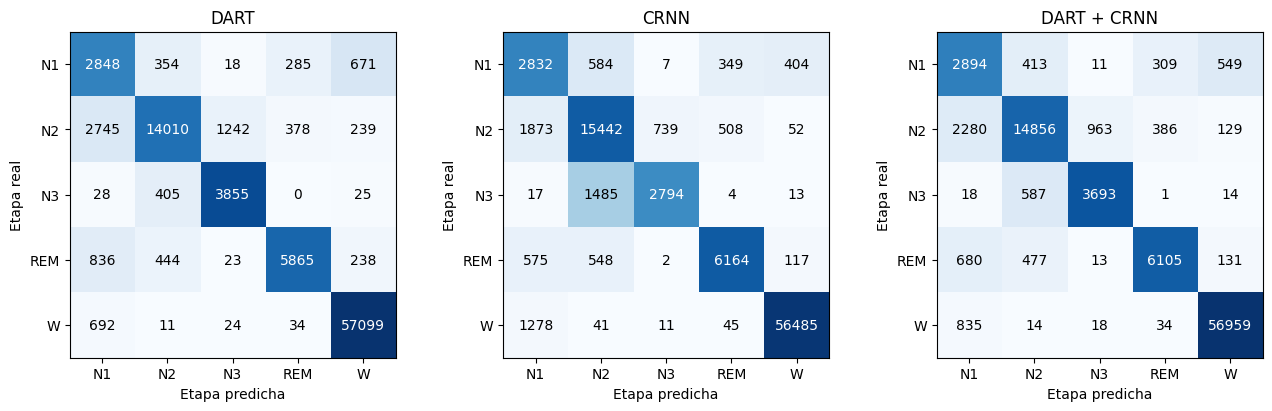

In [9]:
fig, axes = plt.subplots(1,3,figsize=(13,4),layout='constrained')
for ax,m in zip(axes,modelos):
    cm = confusion_matrix(test.etapa,resultados[m],labels=CLASES)
    porcentajes = cm/cm.sum(axis=1,keepdims=True)
    ax.imshow(porcentajes,vmin=0,vmax=1,cmap='Blues')
    for (i,j),n in np.ndenumerate(cm):
        ax.text(j,i,str(n),ha='center',va='center',color='white' if porcentajes[i,j]>.55 else 'black')
    ax.set(xticks=range(5),xticklabels=CLASES,yticks=range(5),yticklabels=CLASES,
           title=m,xlabel='Etapa predicha',ylabel='Etapa real')
plt.show()

## Tiempos de la evaluación 80/20

Los tiempos del manifiesto corresponden al ajuste de cada rama con las 80 personas de entrenamiento y excluyen el preprocesamiento y la evaluación.

In [1]:
import json
from pathlib import Path
import pandas as pd

raiz = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p/'data.dvc').is_file())
ruta = raiz/'data/models/dart_crnn_mixto/evaluacion_80_20/manifest.json'
tiempos = json.loads(ruta.read_text('utf8'))['tiempos_s']
display(pd.Series(tiempos, name='Segundos de entrenamiento').rename(index=str.upper).round(1).to_frame())

,Segundos de entrenamiento
DART,1626.5
CRNN,175.8


## Datos para reproducir esta corrida

La evaluación publicada utiliza 197 noches de 100 personas. Las salidas del notebook de evaluación se pueden consultar en GitHub. Para recuperar los EDF, las características y los pesos de esta instantánea desde el remoto DVC del proyecto, comprueba que tu archivo local `data.dvc` contiene este puntero y ejecuta `dvc pull data.dvc` desde la raíz del repositorio. Se necesitan las credenciales de lectura del remoto R2.

```yaml
outs:
- md5: 08de8e50f02834cf42e8a2aea2805917.dir
  size: 21924394614
  nfiles: 1444
  hash: md5
  path: data
```

## Cargar los modelos entrenados con el 80 % de las personas

Para omitir el entrenamiento, abre un kernel nuevo y ejecuta **únicamente la celda siguiente** después de descargar la instantánea DVC indicada arriba. Carga los pesos de DART y CRNN utilizados para producir las métricas y matrices de este informe.

El ajuste utilizó **80 personas y 158 noches** (62 personas de Cassette y 18 de Telemetry). Las otras **20 personas y 39 noches** se reservaron para la evaluación. La celda deja disponibles los modelos en dart_80 y crnn_80, el manifiesto en ficha_80 y el orden de las etapas en clases_80.

In [1]:
import hashlib
import json
from pathlib import Path

import lightgbm as lgb
import tensorflow as tf

raiz_80 = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p/'data.dvc').is_file())
carpeta_80 = raiz_80/'data/models/dart_crnn_mixto/versiones/100_personas_197_noches/evaluacion_80_20'
manifiesto_80 = carpeta_80/'manifest.json'
if not manifiesto_80.is_file():
    raise FileNotFoundError('Falta la evaluación publicada. Recupera la instantánea DVC indicada en la sección anterior.')

ficha_80 = json.loads(manifiesto_80.read_text(encoding='utf8'))
contrato_80 = ficha_80['contrato']
firma_80 = hashlib.sha256(json.dumps(contrato_80, sort_keys=True, ensure_ascii=False).encode('utf8')).hexdigest()
firma_publicada = 'b5d0a00d4df5b89126dbba8d65f0d1696186b64c8ac80d0e603ba1e3a6a37398'
if firma_80 != firma_publicada or ficha_80['firma'] != firma_publicada:
    raise ValueError('El manifiesto no corresponde al ajuste 80/20 de este informe.')

personas_80 = set(contrato_80['personas_entrenamiento'])
noches_80 = contrato_80['registros_entrenamiento']
if (len(personas_80), len(noches_80), contrato_80['segmentos_entrenamiento']) != (80, 158, 365283):
    raise ValueError('La población de entrenamiento no coincide con el ajuste 80/20.')

pesos_80 = {}
for rama in ('dart', 'crnn'):
    datos_peso = ficha_80['archivos'][rama]
    ruta_peso = carpeta_80/datos_peso['nombre']
    if hashlib.sha256(ruta_peso.read_bytes()).hexdigest() != datos_peso['sha256']:
        raise ValueError(f'La huella del modelo {rama} no coincide con el manifiesto.')
    pesos_80[rama] = ruta_peso

dart_80 = lgb.Booster(model_file=str(pesos_80['dart']))
crnn_80 = tf.keras.models.load_model(pesos_80['crnn'], compile=False)
clases_80 = contrato_80['clases']
print(f'DART y CRNN cargados. Entrenamiento: {len(personas_80)} personas, {len(noches_80)} noches.')
print('Evaluación reservada: 20 personas, 39 noches. Etapas:', ', '.join(clases_80))

DART y CRNN cargados. Entrenamiento: 80 personas, 158 noches.
Evaluación reservada: 20 personas, 39 noches. Etapas: N1, N2, N3, REM, W
